In [71]:
import pandas as pd

df = pd.read_csv("data/fed_r_d_spending.csv")

In [72]:
df.head(20)

,department,year,rd_budget,total_outlays,discretionary_outlays,gdp
0,DOD,1976,3.569600e+10,3.718000e+11,1.756000e+11,1.790000e+12
1,NASA,1976,1.251300e+10,3.718000e+11,1.756000e+11,1.790000e+12
2,DOE,1976,1.088200e+10,3.718000e+11,1.756000e+11,1.790000e+12
3,HHS,1976,9.226000e+09,3.718000e+11,1.756000e+11,1.790000e+12
4,NIH,1976,8.025000e+09,3.718000e+11,1.756000e+11,1.790000e+12
5,NSF,1976,2.372000e+09,3.718000e+11,1.756000e+11,1.790000e+12
6,USDA,1976,1.837000e+09,3.718000e+11,1.756000e+11,1.790000e+12
7,Interior,1976,1.152000e+09,3.718000e+11,1.756000e+11,1.790000e+12
8,DOT,1976,1.142000e+09,3.718000e+11,1.756000e+11,1.790000e+12
9,EPA,1976,9.680000e+08,3.718000e+11,1.756000e+11,1.790000e+12


In [73]:
df.shape

(588, 6)

In [74]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 588 entries, 0 to 587
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   department             588 non-null    str    
 1   year                   588 non-null    int64  
 2   rd_budget              588 non-null    float64
 3   total_outlays          588 non-null    float64
 4   discretionary_outlays  588 non-null    float64
 5   gdp                    588 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 27.7 KB


## Separating the Data

The original dataset contains both department-level R&D budgets and national-level data. I separated them into two DataFrames because they represent different observational units. I also used `drop_duplicates()` to remove repeated national data for each year.

In [75]:
df_department = df[['department', 'year', 'rd_budget']]

df_department.head()

,department,year,rd_budget
0,DOD,1976,3.569600e+10
1,NASA,1976,1.251300e+10
2,DOE,1976,1.088200e+10
3,HHS,1976,9.226000e+09
4,NIH,1976,8.025000e+09


In [76]:
df_national = df[['year', 'total_outlays', 'discretionary_outlays', 'gdp']]

df_national.head()

,year,total_outlays,discretionary_outlays,gdp
0,1976,3.718000e+11,1.756000e+11,1.790000e+12
1,1976,3.718000e+11,1.756000e+11,1.790000e+12
2,1976,3.718000e+11,1.756000e+11,1.790000e+12
3,1976,3.718000e+11,1.756000e+11,1.790000e+12
4,1976,3.718000e+11,1.756000e+11,1.790000e+12


In [77]:
df_national = df_national.drop_duplicates()

df_national.head()

,year,total_outlays,discretionary_outlays,gdp
0,1976,3.718000e+11,1.756000e+11,1.790000e+12
14,1977,4.092000e+11,1.971000e+11,2.028000e+12
28,1978,4.587000e+11,2.187000e+11,2.278000e+12
42,1979,5.040000e+11,2.400000e+11,2.570000e+12
56,1980,5.909000e+11,2.763000e+11,2.797000e+12


In [78]:
print(df_department.shape)
print(df_national.shape)

(588, 3)
(42, 4)


## Reshaping Data

Used `pd.melt()` to convert the two federal outlay columns into a type column and a outlay column. This will make it easier to compare different types of spending.

In [79]:
df_outlays = pd.melt(
    df_national,
    id_vars=['year'],
    value_vars=['total_outlays', 'discretionary_outlays'],
    var_name='type',
    value_name='amount'
)

df_outlays.head()

,year,type,amount
0,1976,total_outlays,3.718000e+11
1,1977,total_outlays,4.092000e+11
2,1978,total_outlays,4.587000e+11
3,1979,total_outlays,5.040000e+11
4,1980,total_outlays,5.909000e+11


### Cleaning Column Names

I used `str.split()` to separate the spending type from the word "outlays." Then I removed the unnecessary columns because they contained repeated information. The final table has three columns.

In [80]:
df_outlays[["spending_type", "measure"]] = df_outlays["type"].str.split("_", expand=True)

df_outlays.head()

,year,type,amount,spending_type,measure
0,1976,total_outlays,3.718000e+11,total,outlays
1,1977,total_outlays,4.092000e+11,total,outlays
2,1978,total_outlays,4.587000e+11,total,outlays
3,1979,total_outlays,5.040000e+11,total,outlays
4,1980,total_outlays,5.909000e+11,total,outlays


In [81]:
df_outlays = df_outlays[["year", "spending_type", "amount"]]

df_outlays.head()

,year,spending_type,amount
0,1976,total,3.718000e+11
1,1977,total,4.092000e+11
2,1978,total,4.587000e+11
3,1979,total,5.040000e+11
4,1980,total,5.909000e+11


## Pivot Table

I used a pivot table to calculate the average R&D budget for each department. This allows me to compare the budgets across different departments.

In [82]:
df_pivot = pd.pivot_table(
    df_department,
    values="rd_budget",
    index="department",
    aggfunc="mean"
)

df_pivot.head()

,rd_budget
department,
DHS,3.790000e+08
DOC,1.231500e+09
DOD,6.468519e+10
DOE,1.188338e+10
DOT,9.177857e+08


In [83]:
df_pivot = df_pivot.sort_values("rd_budget", ascending=False)

df_pivot.head()

,rd_budget
department,
DOD,6.468519e+10
HHS,2.229676e+10
NIH,2.111757e+10
NASA,1.214026e+10
DOE,1.188338e+10


## Data Visualization

### Average R&D Budget by Department

I created a bar chart to compare the five departments with the highest average R&D budgets. This makes it easier to see the differences between departments.

In [84]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


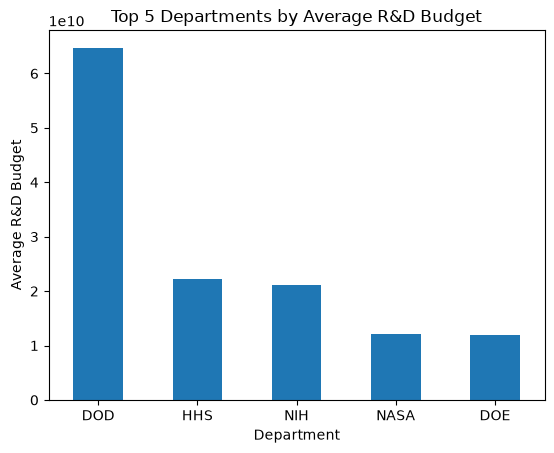

In [85]:
import matplotlib.pyplot as plt

df_pivot.head().plot(kind="bar", legend=False)

plt.title("Top 5 Departments by Average R&D Budget")
plt.xlabel("Department")
plt.ylabel("Average R&D Budget")
plt.xticks(rotation=0)
plt.show()

The chart shows that DOD had the highest average R&D budget, much higher than the other departments and agencies. HHS was the second and NIH was the third. This suggests that defense-related R&D received particularly large funding during the years.

### Federal Spending Over Time

I created a line chart to compare total federal outlays and discretionary outlays from 1976 to 2017.

In [86]:
df_plot = df_outlays.pivot(
    index="year",
    columns="spending_type",
    values="amount"
)

df_plot.head()

spending_type,discretionary,total
year,,
1976,1.756000e+11,3.718000e+11
1977,1.971000e+11,4.092000e+11
1978,2.187000e+11,4.587000e+11
1979,2.400000e+11,5.040000e+11
1980,2.763000e+11,5.909000e+11


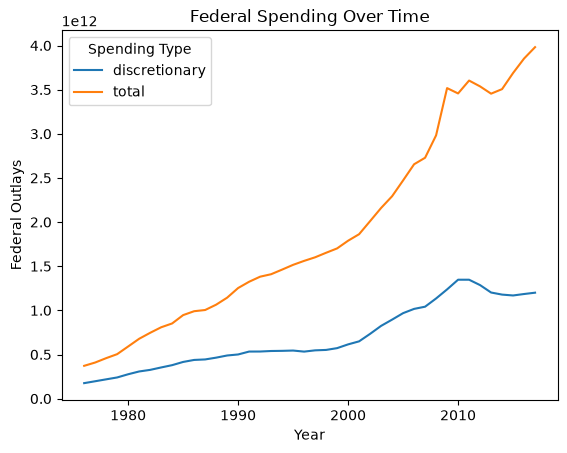

In [87]:
df_plot.plot(kind="line")

plt.title("Federal Spending Over Time")
plt.xlabel("Year")
plt.ylabel("Federal Outlays")
plt.legend(title="Spending Type")
plt.show()

The line chart shows that total federal outlays increased from 1976 to 2017. Total outlays were consistently higher than discretionary outlays.